# Controlled SINDy + LQR

Discovers a sparse discrete-time controlled model, prints the learned equations, linearizes at the upright equilibrium, and computes LQR.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from models.dataset_views import load_control_dataset
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics
from visualization import plot_states_and_input, animate_cart_pendulum

DATASET = ROOT / "data/full_example/random_walk_dataset.npz"
ds = load_control_dataset(DATASET)
print(ds.states.shape, ds.inputs.shape, ds.initial_state)


(500, 1000, 4) (500, 1000, 1) [0.01447063 0.06920296 0.17453293 0.84325554]


In [2]:
from controllers.sindy_lqr import SINDyLQRController, train_sindy_lqr

ARTIFACT = ROOT / "artifacts/controllers/sindy_lqr.pkl"
FORCE_LIMIT = 5.0

if ARTIFACT.exists():
    controller = SINDyLQRController.load(ARTIFACT)
    if float(getattr(controller, "force_limit", 1.0)) < 4.5:
        print(f"  Artifact force_limit={controller.force_limit} N is below 4.5 N — retraining.")
        ARTIFACT.unlink()
if not ARTIFACT.exists():
    controller = train_sindy_lqr(ds, seed=0, force_limit=FORCE_LIMIT, t_end=20.0, dt=0.02)
    controller.save(ARTIFACT)
    print(f"saved {ARTIFACT}")
else:
    print(f"loaded {ARTIFACT}  (force_limit={controller.force_limit}  alpha={controller.metadata.get('alpha')})")
for eq in controller.metadata["model"]["equations"]:
    print(eq)
controller.metadata


loaded /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/controllers/sindy_lqr.pkl  (force_limit=5.0  alpha=0.5)
x_next = 1*x + 0.01003*x_dot
x_dot_next = 0.9999*x_dot + 0.007078*u + -0.02327*sin(theta)
theta_next = 1*theta + 0.01002*theta_dot
theta_dot_next = 0.9998*theta_dot + 0.2135*sin(theta) + 0.01827*u*cos(theta)


{'runtime_train_sec': 0.49789493000207585,
 'A': [[0.999995851519853, 0.010031553770214224, 0.0, 0.0],
  [0.0, 0.9999478545422488, -0.023266956453411668, 0.0],
  [0.0, 0.0, 0.9999944124685879, 0.010021439293968773],
  [0.0, 0.0, 0.21353049220287026, 0.9998142180495327]],
 'B': [[0.0], [0.007078023965012598], [0.0], [0.018268125600516744]],
 'K': [[-3.829077481282635,
   -6.986664769319947,
   75.10769857649002,
   17.95297514522417]],
 'alpha': 0.5,
 'P': [[182.4905615306721,
   156.05718249989724,
   -468.5660049336675,
   -74.7390112366391],
  [156.05718249989724,
   239.19334282489842,
   -775.7279785561061,
   -118.5794349462783],
  [-468.5660049336675,
   -775.7279785561061,
   6411.724731704446,
   566.222409505564],
  [-74.7390112366391,
   -118.5794349462783,
   566.222409505564,
   110.21963317755122]],
 'Q': [[1.0, 0.0, 0.0, 0.0],
  [0.0, 0.2, 0.0, 0.0],
  [0.0, 0.0, 100.0, 0.0],
  [0.0, 0.0, 0.0, 10.0]],
 'R': [[0.05]],
 'model': {'config': {'threshold': 0.005,
   'ridge': 1

In [3]:
T_END = 20.0
DT    = 0.02


def run_fixed_and_jittered(controller, n_jitter=8, seed=0):
    rng = np.random.default_rng(seed)
    jitter_scale = np.array([0.02, 0.05, 0.03, 0.1])
    force_limit = float(getattr(controller, "force_limit", 5.0))
    cases = [("fixed", ds.initial_state)]
    for i in range(n_jitter):
        cases.append((f"jitter_{i:02d}", ds.initial_state + rng.normal(scale=jitter_scale)))
    rows, rollouts = [], {}
    for label, x0 in cases:
        result = rollout_controller(controller, x0, t_end=T_END, dt=DT, force_limit=force_limit)
        metrics = rollout_metrics(result.t, result.y, result.u, result.control_times_sec)
        rows.append({"case": label, **metrics})
        rollouts[label] = result
    # Successes first, then by cost
    rows.sort(key=lambda r: (not bool(r.get("success")), float(r.get("cost", np.inf))))
    return rows, rollouts


def show_case(label, result, title):
    fig, axes = plot_states_and_input(result.t, result.y, result.u, title=title, theta_in_degrees=True)
    plt.show()

    metrics = rollout_metrics(result.t, result.y, result.u)
    t_settle = metrics.get("settle_and_remain_time")
    t = result.t
    theta_deg = np.degrees(result.y[2, :])
    success = bool(metrics.get("success", False))

    fig2, axes2 = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    ax = axes2[0]
    ax.plot(t, theta_deg, color="steelblue", linewidth=1.5, label="\u03b8 (deg)")
    ax.axhline( 2.0, color="green", linestyle="--", linewidth=1, label="\u00b12\u00b0 tolerance")
    ax.axhline(-2.0, color="green", linestyle="--", linewidth=1)
    if t_settle is not None:
        ax.axvspan(t_settle, float(t[-1]), alpha=0.13, color="green",
                   label=f"Settled  t_s={t_settle:.2f} s")
    ax.axvline(float(t[-1]) / 2, color="gray", linestyle=":", linewidth=1, label="t_end/2")
    ax.set_ylabel("\u03b8 (degrees)")
    ax.set_title(f"{title}  \u2014  {'\u2713 SUCCESS' if success else '\u2717 FAIL'}")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

    ax2 = axes2[1]
    ax2.plot(t, result.u, color="darkorange", linewidth=1.4, label="Force (N)")
    ax2.axhline(0, color="k", linewidth=0.5)
    ax2.set_xlabel("time (s)")
    ax2.set_ylabel("force (N)")
    ax2.legend(loc="upper right", fontsize=8)
    ax2.grid(True, alpha=0.3)
    fig2.tight_layout()
    plt.show()

    if t_settle is not None:
        post = float(t[-1]) - t_settle
        flag = "PASS" if t_settle <= float(t[-1]) / 2 else "FAIL"
        print(f"  settle_t={t_settle:.2f} s  post_settle={post:.2f} s  "
              f"[{flag}: t_s \u2264 {float(t[-1])/2:.0f} s]")
    else:
        print("  Did not settle and remain within all tolerances.")
    try:
        anim = animate_cart_pendulum(result.t, result.y, pendulum_length=0.5, stride=5)
        display(HTML(anim.to_jshtml()))
    except Exception as exc:
        print(f"  Animation skipped ({exc})")


In [4]:
rows, rollouts = run_fixed_and_jittered(controller, n_jitter=8, seed=5)
successes = sum(1 for r in rows if r.get("success"))
print(f"Successes: {successes}/{len(rows)}  (force_limit={getattr(controller,'force_limit',5.0)} N, t_end={T_END} s)")
for r in rows:
    t_s = r.get("settle_and_remain_time")
    t_s_str = f"{t_s:.2f} s" if t_s is not None else "  None  "
    print(f"  {r['case']:15s}  success={str(r.get('success')):5s}  "
          f"settle_t={t_s_str:8s}  cost={r.get('cost', float('inf')):.4g}")
rows[:3]


Successes: 9/9  (force_limit=5.0 N, t_end=20.0 s)
  jitter_06        success=True   settle_t=3.12 s    cost=2.165
  jitter_07        success=True   settle_t=3.36 s    cost=3.036
  jitter_03        success=True   settle_t=3.36 s    cost=3.112
  jitter_01        success=True   settle_t=3.38 s    cost=3.121
  jitter_02        success=True   settle_t=3.48 s    cost=3.665
  jitter_04        success=True   settle_t=3.48 s    cost=3.678
  jitter_05        success=True   settle_t=3.56 s    cost=4.227
  fixed            success=True   settle_t=3.74 s    cost=5.503
  jitter_00        success=True   settle_t=3.78 s    cost=6.116


[{'case': 'jitter_06',
  'finite': True,
  'final_abs_theta': 5.78365314370056e-11,
  'final_abs_theta_dot': 8.706711642221279e-11,
  'final_abs_x': 1.1333776856907944e-09,
  'final_abs_x_dot': 1.2266979644335521e-09,
  'max_abs_theta': 0.17816267620791548,
  'max_abs_x': 0.7751864430961954,
  'control_energy': 9.163998707879802,
  'mean_abs_force': 0.18583717232293898,
  'cost': 2.1651217977430925,
  'settling_time_theta_2deg': 1.8,
  'settle_and_remain_time': 3.12,
  'post_settle_duration': 16.88,
  'settled_fraction': 0.8441558441558441,
  'post_settle_max_theta': 0.019534650161452317,
  'no_fall': True,
  'success': True,
  'runtime_control_ms_per_step': 0.0940100129642982},
 {'case': 'jitter_07',
  'finite': True,
  'final_abs_theta': 7.070614375731105e-11,
  'final_abs_theta_dot': 1.0811711204671497e-10,
  'final_abs_x': 1.3969817880251003e-09,
  'final_abs_x_dot': 1.5096315076593706e-09,
  'max_abs_theta': 0.19567739775962315,
  'max_abs_x': 0.9535756088431604,
  'control_energy

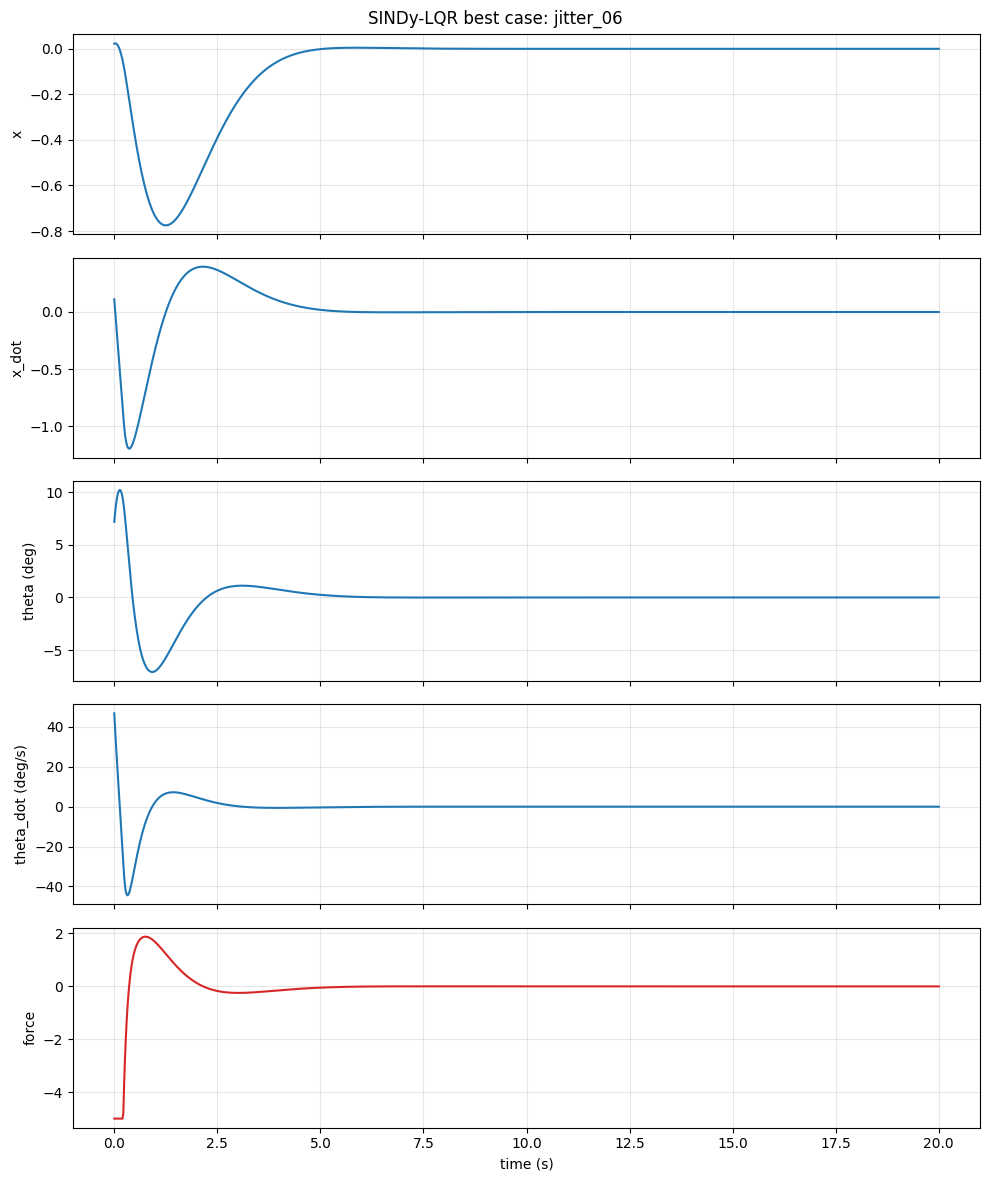

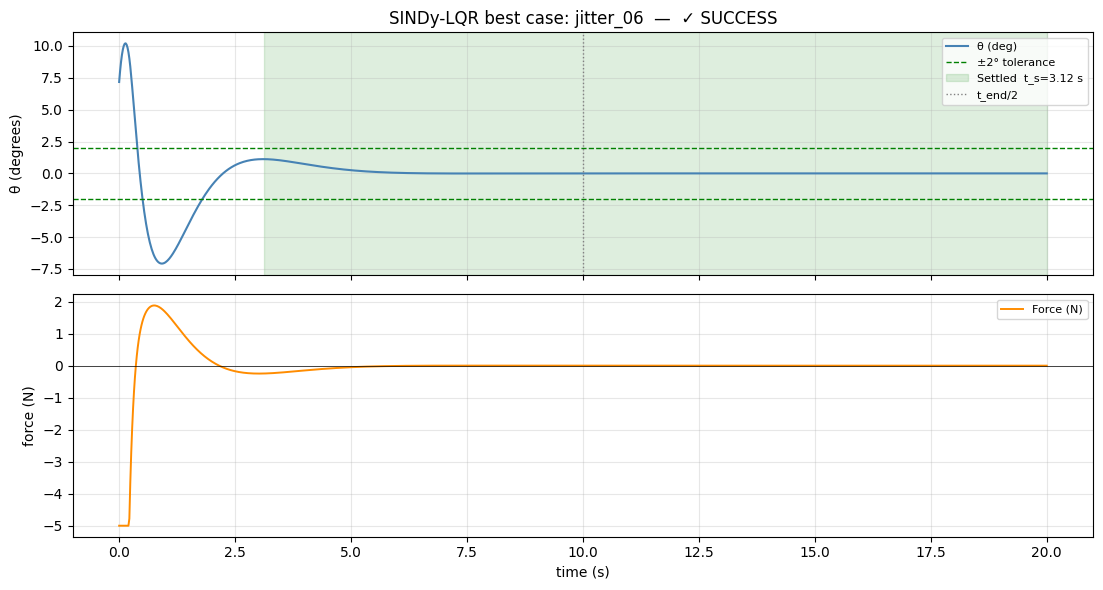

  settle_t=3.12 s  post_settle=16.88 s  [PASS: t_s ≤ 10 s]


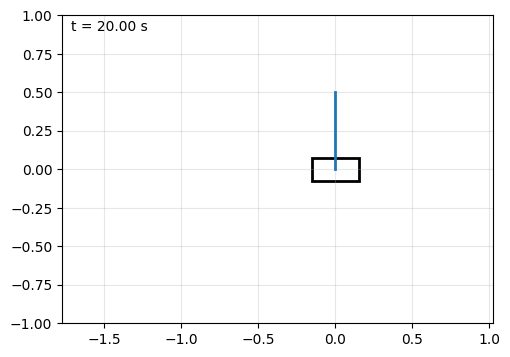

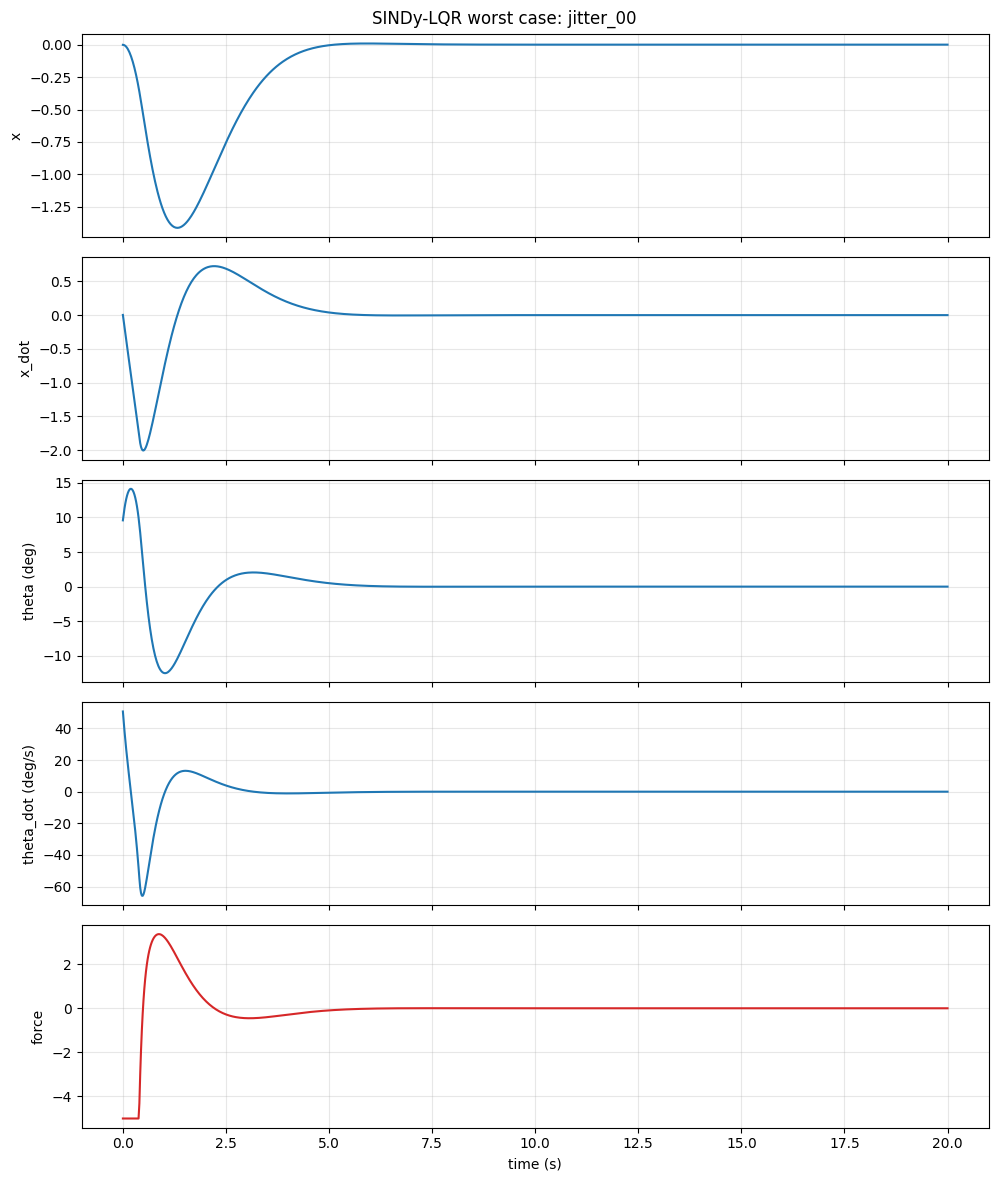

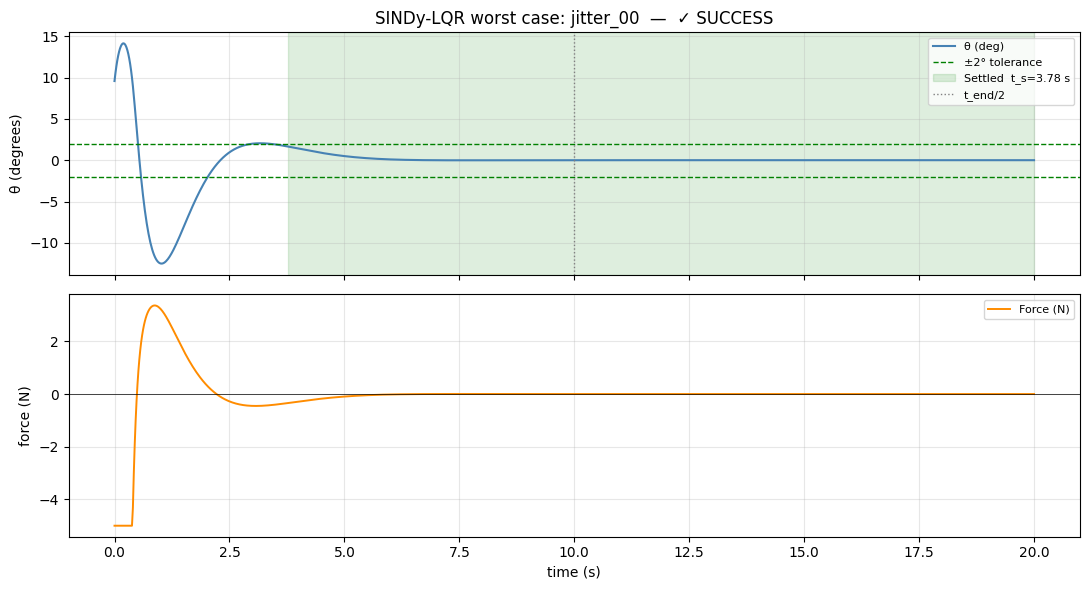

  settle_t=3.78 s  post_settle=16.22 s  [PASS: t_s ≤ 10 s]


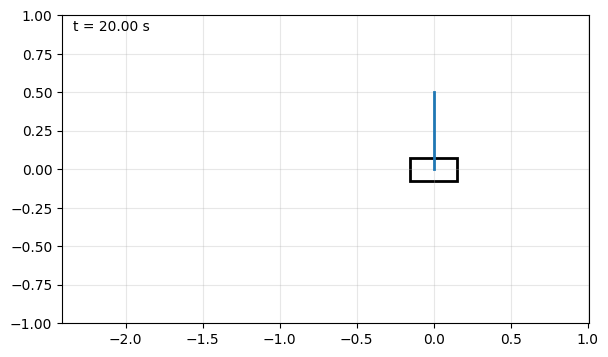

In [5]:
best  = rows[0]["case"]
worst = rows[-1]["case"]
show_case(best,  rollouts[best],  f"SINDy-LQR best case: {best}")
show_case(worst, rollouts[worst], f"SINDy-LQR worst case: {worst}")
